# 01b - Inspect raw ISMN data (no filtering)

Reads directly from the same raw ISMN zip as
[`01_download_ismn_data.ipynb`](01_download_ismn_data.ipynb), via the vendored
`ISMN_funcs.interface.ISMN_Interface` reader, but applies **none** of that
notebook's filtering, so every sensor and every reading can be inspected
visually before deciding what to exclude:

- **No depth-band restriction.** `01_download_ismn_data.ipynb` only keeps
  sensors in `(0.04, 0.06)` and `(0.19, 0.21)` m. Here `get_dataset_ids` is
  called with `(0, 50)` m -- `get_dataset_ids` always requires *some* depth
  window (there's no "no depth filter" option), so 50 m is used as a value
  comfortably beyond any real in-situ soil-moisture sensor, making this
  effectively unrestricted -- so any sensor at a depth the download notebook
  silently drops (e.g. a ~10cm sensor) still shows up here.
- **No quality-flag filtering.** `01_download_ismn_data.ipynb` keeps only
  `soil_moisture_flag == 'G'` readings. Here every reading is kept regardless
  of flag, with the flag value used only to *color* points for visual
  triage, never to drop them.
- **No fault-plateau masking, no zero-clipping, no minimum-readings cutoff**
  (the extra cleanup `Checks_alaska.ipynb`'s `read_insitu` applies downstream)
  -- this notebook is upstream of all of that.

Point `ISMN_data` below at the same zip `01_download_ismn_data.ipynb` uses.

In [1]:
import sys
import os
from pathlib import Path

import pyproj
pyproj.datadir.set_data_dir(os.path.join(sys.prefix, "Library", "share", "proj"))

REPO_ROOT = os.path.dirname(os.getcwd())
if REPO_ROOT not in sys.path:
    sys.path.append(REPO_ROOT)
from ISMN_funcs.interface import ISMN_Interface

# Repo root (NISAR4SM/), two levels above this notebook's own directory
# (Earsel26_NISAR-main/notebooks/) -- not the same as
# REPO_ROOT above, which only goes up one level (for the ISMN_funcs import).
PROJECT_ROOT = Path.cwd().parents[1]

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

C:\Users\geoka\miniconda3\envs\nisar-era5\Lib\site-packages\pyproj\network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


## 1. Load the raw ISMN bundle

In [2]:
ISMN_data = str(PROJECT_ROOT / "Data_separate_files_header_20260529_20260831_13743_SU1V_20260901.zip")

ismn_data = ISMN_Interface(ISMN_data)

print('Network: [Stations]\n', ismn_data.collection)

Found existing ismn metadata in D:\Docs\RS_2023\NISAR4SM\python_metadata\Data_separate_files_header_20260529_20260831_13743_SU1V_20260901.csv.
Network: [Stations]
 SCAN: ['MooseInc'],
SNOTEL: ['Aniak', 'AtigunPass', 'Coldfoot', 'EagleSummit', 'GobblersKnob', 'GraniteCrk', 'ImnaviatCreek', 'LittleChenaRidge', 'McGrath', 'Nenana', 'NukaGlacier', 'PilgrimHotSprings', 'PrudhoeBay', 'RockyPoint', 'SpringCreek', 'SusitnaValleyHigh', 'TurnagainPass', 'UpperNomeCreek'],
USCRN: ['Kenai-29-ENE']


## 2. Every soil_moisture sensor, any depth

`check_only_sensor_depth_from=False` (the default) means a sensor is kept if
its whole `[depth_from, depth_to]` range falls inside `(0, 50)` m -- true for
every realistic in-situ sensor, so this is the full set.

In [3]:
sm_ids = ismn_data.get_dataset_ids(variable=['soil_moisture'], min_depth=0, max_depth=50)
print(f"{len(sm_ids)} soil_moisture sensor(s) found across all depths")

44 soil_moisture sensor(s) found across all depths


## 3. Read every sensor, raw -- no flag filtering

Keeps `soil_moisture`, `soil_moisture_flag`, and `soil_moisture_orig_flag` for
every timestamp exactly as ISMN reports it. `sensors` is a list of dicts, one
per sensor id, holding both the metadata and the raw dataframe.

In [4]:
sensors = []
for sm_id in sm_ids:
    df, meta = ismn_data.read(sm_id, return_meta=True)
    sensors.append({
        "id": sm_id,
        "network": meta.network.val,
        "station": meta.station.val,
        "instrument": meta.instrument.val,
        "depth_from": float(meta.instrument.depth_from),
        "depth_to": float(meta.instrument.depth_to),
        "df": df,
    })

sensors.sort(key=lambda s: (s["station"], s["depth_from"], s["instrument"]))
print(f"Read {len(sensors)} sensor(s)")

Read 44 sensor(s)


## 4. Summary table

One row per sensor: station, network, instrument, depth range, total reading
count, a breakdown of every `soil_moisture_flag` value present (not just
`'G'`), and the raw timestamp range -- nothing here has been dropped or
cleaned.

In [5]:
rows = []
for s in sensors:
    df = s["df"]
    flag_counts = df["soil_moisture_flag"].value_counts().to_dict()
    rows.append({
        "station": s["station"],
        "network": s["network"],
        "instrument": s["instrument"],
        "depth_from": s["depth_from"],
        "depth_to": s["depth_to"],
        "n_readings": len(df),
        "flag_counts": flag_counts,
        "start": df.index.min(),
        "end": df.index.max(),
    })

summary = pd.DataFrame(rows)
pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", None)
summary

,station,network,instrument,depth_from,depth_to,n_readings,flag_counts,start,end
0,Aniak,SNOTEL,not-specified_2_1,0.0508,0.0508,2257,"{'G': 2203, 'C03': 51, 'D02': 3}",2026-05-29,2026-08-31 00:00:00
1,Aniak,SNOTEL,not-specified_2_1,0.1016,0.1016,2257,"{'G': 2107, 'C03': 147, 'D02': 3}",2026-05-29,2026-08-31 00:00:00
2,Aniak,SNOTEL,not-specified_2_1,0.2032,0.2032,2257,"{'G': 2095, 'C03': 159, 'D02': 3}",2026-05-29,2026-08-31 00:00:00
3,AtigunPass,SNOTEL,not-specified_2_1,0.0508,0.0508,2255,"{'G': 1414, 'D01': 396, 'D01,D02': 292, 'D02': 141, 'D06,D01,D02': 6, 'D06,D01': 4, 'D08': 1, 'C02,C03,D01': 1}",2026-05-29,2026-08-31 00:00:00
4,AtigunPass,SNOTEL,not-specified_3_1,0.2032,0.2032,2255,"{'G': 1491, 'D01': 320, 'D01,D02': 234, 'D02': 199, 'D06,D01,D02': 6, 'D06,D01': 3, 'D08': 2}",2026-05-29,2026-08-31 00:00:00
5,Coldfoot,SNOTEL,not-specified_2_1,0.0508,0.0508,2252,"{'G': 2163, 'D10': 65, 'D02': 22, 'D08': 1, 'D07': 1}",2026-05-29,2026-08-31 00:00:00
6,Coldfoot,SNOTEL,not-specified_4_1,0.2032,0.2032,2252,"{'G': 2229, 'D02': 22, 'D08': 1}",2026-05-29,2026-08-31 00:00:00
7,EagleSummit,SNOTEL,not-specified_2_1,0.0508,0.0508,2253,"{'G': 2089, 'D01': 143, 'D02': 17, 'D08': 2, 'D08,D01': 1, 'D06,D01': 1}",2026-05-29,2026-08-31 00:00:00
8,EagleSummit,SNOTEL,not-specified_2_1,0.2032,0.2032,2253,"{'G': 1812, 'D01': 236, 'D10': 188, 'D02': 10, 'D01,D02': 7}",2026-05-29,2026-08-31 00:00:00
9,GobblersKnob,SNOTEL,not-specified_4_1,0.0508,0.0508,1271,"{'G': 1266, 'D02': 5}",2026-05-29,2026-07-20 22:00:00


## 5. Per-sensor raw time series, colored by flag

One subplot per sensor (station x instrument x depth), every reading plotted
regardless of flag -- `'G'` (good) in a neutral color, every other flag value
in a distinct warning color from `FLAG_COLORS` (extended automatically if a
flag not seen yet turns up). This is deliberately the same fixed y-axis
`[0, 60]`% used in `Checks_alaska.ipynb`'s per-station overview, so a sensor
with implausible outliers (negative, near-zero plateaus, spikes) stands out
directly instead of being rescaled away by its own subplot.

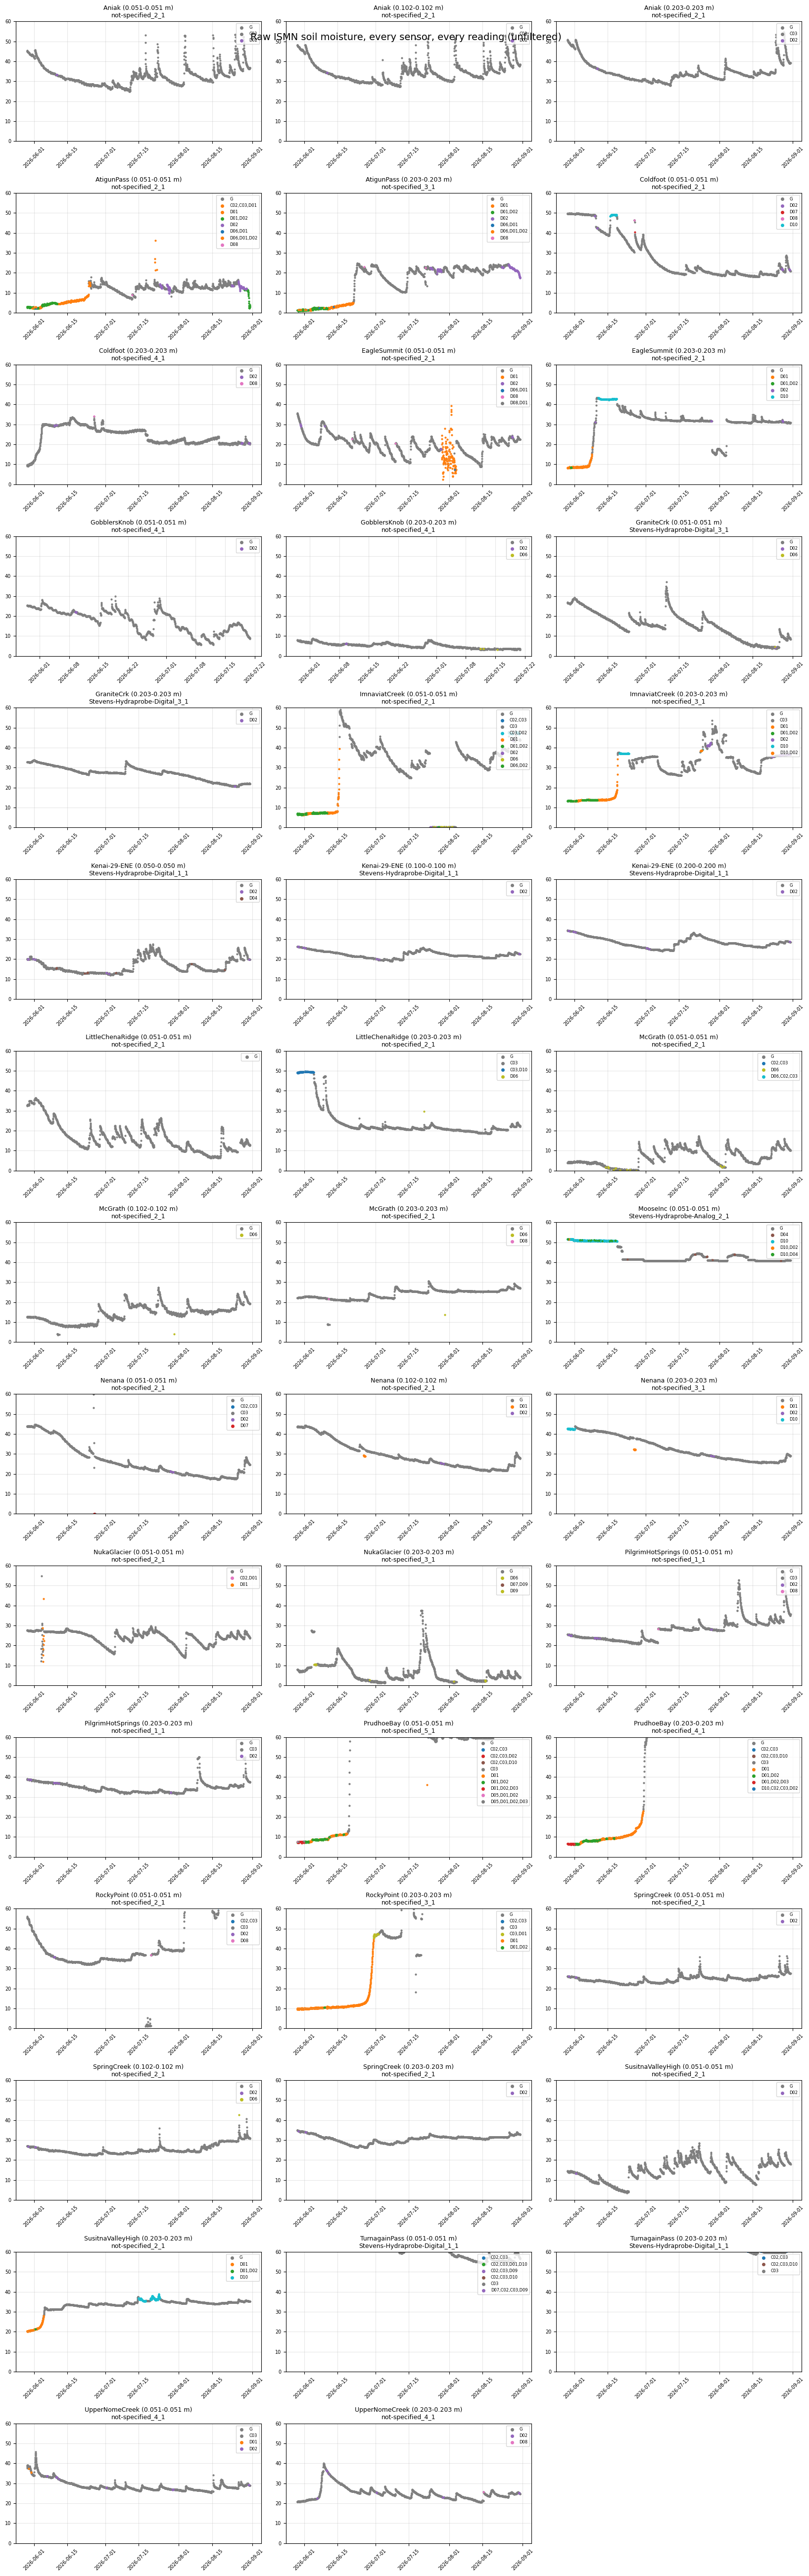

In [6]:
SM_YLIM = (0, 60)

all_flags = sorted(set().union(*(set(s["df"]["soil_moisture_flag"].unique()) for s in sensors)))
palette = plt.cm.tab10(np.linspace(0, 1, 10))
FLAG_COLORS = {"G": "tab:gray"}
other_flags = [f for f in all_flags if f != "G"]
for i, flag in enumerate(other_flags):
    FLAG_COLORS[flag] = palette[i % len(palette)]

ncols = 3
nrows = int((len(sensors) + ncols - 1) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 5.5, nrows * 3.5), squeeze=False)
axes = axes.flatten()

for idx, s in enumerate(sensors):
    ax = axes[idx]
    df = s["df"]
    sm_pct = df["soil_moisture"] * 100
    for flag, color in FLAG_COLORS.items():
        m = df["soil_moisture_flag"] == flag
        if m.any():
            ax.scatter(df.index[m], sm_pct[m], s=4, color=color, label=str(flag))
    ax.set_ylim(*SM_YLIM)
    ax.set_title(f"{s['station']} ({s['depth_from']:.3f}-{s['depth_to']:.3f} m)\n{s['instrument']}", fontsize=9)
    ax.tick_params(axis="x", rotation=45, labelsize=7)
    ax.tick_params(axis="y", labelsize=7)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=6, loc="upper right", markerscale=2)

for idx in range(len(sensors), len(axes)):
    axes[idx].axis("off")

fig.suptitle("Raw ISMN soil moisture, every sensor, every reading (unfiltered)", fontsize=14)
fig.tight_layout()
plt.show()

## Summary

`sensors` holds the raw dataframe (`soil_moisture`, `soil_moisture_flag`,
`soil_moisture_orig_flag`, full timestamp index) for every sensor at every
depth, and `summary` gives a one-row-per-sensor overview including the full
flag breakdown. Nothing here feeds any other notebook -- it's purely for
visual/manual QC before deciding on depth bands, flag filtering, or any other
cleanup step upstream in `01_download_ismn_data.ipynb` /
`01_prepare_ismn_data.ipynb`.